# Week 4: Predictive Modeling and Optimization in Logistics

## Delivery Time Prediction Using Machine Learning

### Objective

The objective of this project is to develop a machine learning model that predicts delivery time using logistics-related features such as distance, package weight, delivery mode, vehicle type, weather condition, region, and expected delivery time.

The predicted delivery time can help logistics companies improve scheduling, resource allocation, route planning, and delivery performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = pd.read_csv("../data/cleaned_delivery_data.csv")

data.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,0.999659,0.947595,0.421053,0.272727,no,delivered,0.50,1.000000
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,0.293015,0.956397,0.105263,0.045455,no,delivered,1.00,0.354251
2,250.99,shadowfax,groceries,truck,two day,east,rainy,0.919591,0.536745,0.526316,0.636364,no,delivered,0.75,0.879932
3,250.99,dhl,electronics,ev van,same day,east,cold,0.906644,0.246059,0.315789,0.272727,no,delivered,0.50,0.904915
4,250.99,dhl,clothing,van,two day,north,foggy,0.862351,0.744115,0.473684,0.636364,no,delivered,0.75,0.845054


In [3]:
print("Dataset shape:", data.shape)

Dataset shape: (25000, 15)


In [4]:
features = [
    "distance_km",
    "package_weight_kg",
    "expected_time_hours",
    "delivery_mode",
    "vehicle_type",
    "weather_condition",
    "region",
    "delivery_partner"
]

target = "delivery_time_hours"

X = data[features]
y = data[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

Features:
['distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_mode', 'vehicle_type', 'weather_condition', 'region', 'delivery_partner']

Target:
delivery_time_hours


In [5]:
numerical_features = [
    "distance_km",
    "package_weight_kg",
    "expected_time_hours"
]

categorical_features = [
    "delivery_mode",
    "vehicle_type",
    "weather_condition",
    "region",
    "delivery_partner"
]

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 20000
Testing records: 5000


In [8]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [9]:
linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R² Score:", round(linear_r2, 4))

Linear Regression
MAE: 0.0675
RMSE: 0.0854
R² Score: 0.7283


In [12]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [13]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R² Score:", round(rf_r2, 4))

Random Forest
MAE: 0.0697
RMSE: 0.0882
R² Score: 0.7101


In [14]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2
    ]
})

model_results.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.0675,0.0854,0.7283
1,Random Forest,0.0697,0.0882,0.7101


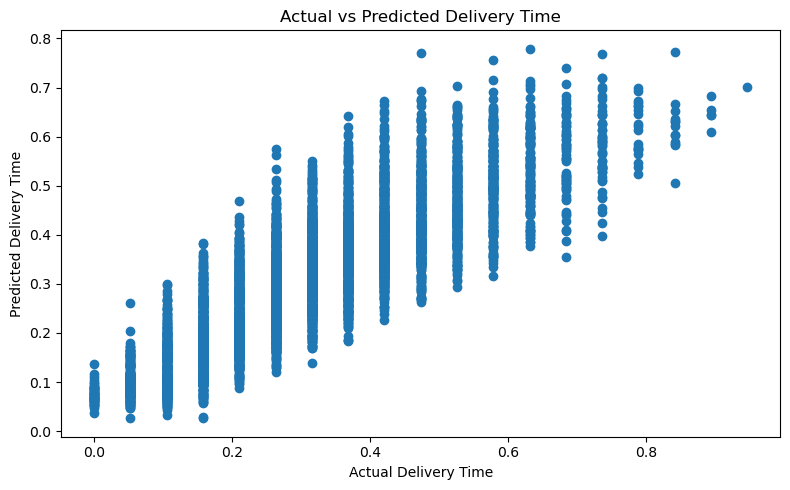

In [15]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, rf_predictions)

plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")
plt.title("Actual vs Predicted Delivery Time")

plt.tight_layout()

plt.savefig(
    "../visualizations/actual_vs_predicted_delivery_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_estimator = rf_model.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

importance = pd.Series(
    rf_estimator.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(10))

num__distance_km                 0.537233
cat__weather_condition_stormy    0.136696
cat__weather_condition_rainy     0.091046
num__package_weight_kg           0.067301
cat__weather_condition_foggy     0.036492
num__expected_time_hours         0.009179
cat__region_central              0.005492
cat__region_west                 0.005441
cat__region_south                0.005406
cat__region_north                0.005371
dtype: float64


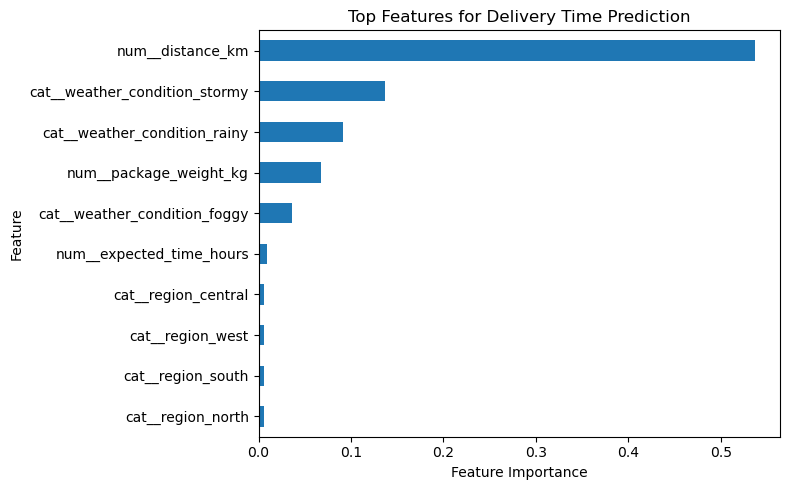

In [17]:
importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8,5)
)

plt.title("Top Features for Delivery Time Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "../visualizations/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()